In [ ]:
# #Text cell <undefined>
# # %% [markdown]
# # 🎓 Student Performance Predictor — Complete ML Pipeline
# **Target:** Predict `math score` from student background features
# **Dataset:** StudentsPerformance.csv (1000 rows)

# ---
# ### 📋 Table of Contents
# 1. Install & Import Libraries
# 2. Load & Explore Data (EDA)
# 3. Data Preprocessing
# 4. Feature Engineering
# 5. Train / Test Split
# 6. Model Training (7 Models)
# 7. Model Evaluation & Comparison
# 8. Hyperparameter Tuning
# 9. Final Model Evaluation
# 10. Save & Load Model
# 11. Predict on New Data

# Text cell <undefined>
# # %% [markdown]
## ⚙️ Step 1 — Install & Import Libraries

#Code cell <undefined>

# Install extra libraries (xgboost already available in Colab)
!pip install -q xgboost catboost

# ── Core ──────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# ── Visualization ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
sns.set_theme(style='darkgrid', palette='muted')
%matplotlib inline

# ── Sklearn ───────────────────────────────────────────────────────────────────
from sklearn.model_selection       import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing         import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose               import ColumnTransformer
from sklearn.pipeline              import Pipeline
from sklearn.metrics               import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model          import LinearRegression, Ridge, Lasso
from sklearn.tree                  import DecisionTreeRegressor
from sklearn.ensemble              import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors             import KNeighborsRegressor

from xgboost  import XGBRegressor
from catboost import CatBoostRegressor

import joblib

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


In [ ]:



# 📂 Step 2 — Load & Explore Data (EDA)



# ── Upload your CSV file ──────────────────────────────────────────────────────

# # METHOD A: Upload manually
# from google.colab import files
# uploaded = files.upload()   # <-- click 'Choose File' and upload StudentsPerformance.csv

# # Load the file
# import io
# df = pd.read_csv(io.BytesIO(uploaded['StudentsPerformance.csv']))

# -------------------------------------------------------------------
# METHOD B: If already in Colab /content folder, use this instead:
df = pd.read_csv('/content/StudentsPerformance.csv')
# -------------------------------------------------------------------

print(f'✅ Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns')
df.head()

✅ Dataset loaded: 1000 rows × 8 columns


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:



# ── Basic info ────────────────────────────────────────────────────────────────
print('── Shape ──')
print(df.shape)

print('\n── Data Types ──')
print(df.dtypes)

print('\n── Missing Values ──')
print(df.isnull().sum())

print('\n── Duplicates ──')
print(f'Duplicate rows: {df.duplicated().sum()}\n\n')


# ── Descriptive statistics ────────────────────────────────────────────────────
print("dataset discription")
df.describe().round(2)

── Shape ──
(1000, 8)

── Data Types ──
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

── Missing Values ──
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

── Duplicates ──
Duplicate rows: 0


dataset discription


,math score,reading score,writing score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00


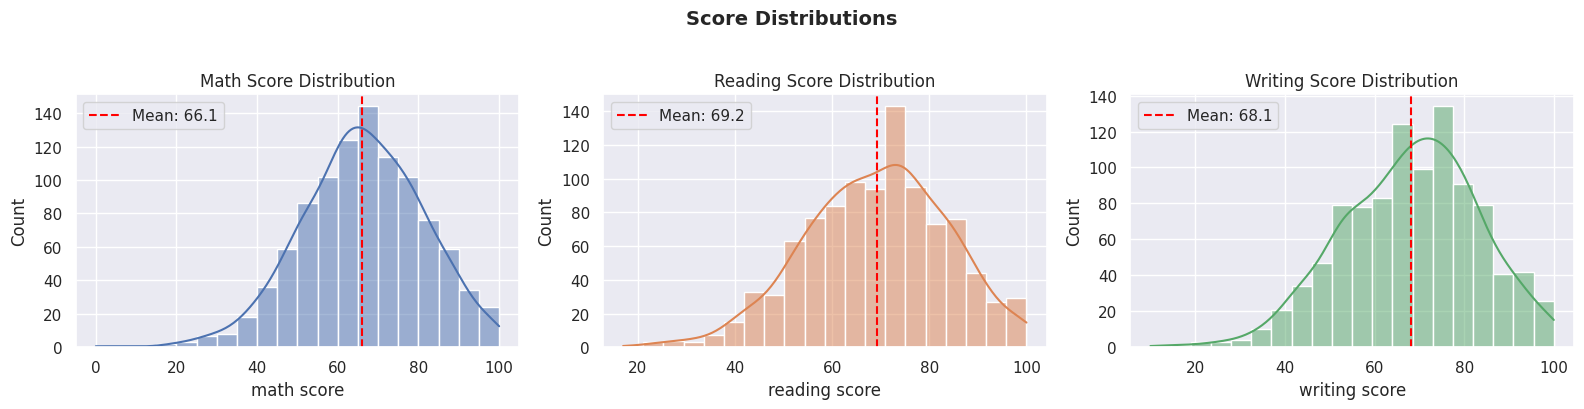

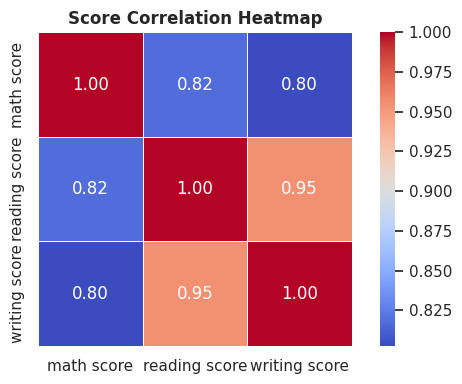

In [ ]:

# ── EDA: Score distributions ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors = ['#4C72B0', '#DD8452', '#55A868']

for ax, col, c in zip(axes, ['math score', 'reading score', 'writing score'], colors):
    sns.histplot(df[col], kde=True, ax=ax, color=c, bins=20)
    ax.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.1f}')
    ax.set_title(f'{col.title()} Distribution')
    ax.legend()

plt.suptitle('Score Distributions', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()



# ── EDA: Correlation heatmap ──────────────────────────────────────────────────
plt.figure(figsize=(6, 4))
corr = df[['math score', 'reading score', 'writing score']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, square=True)
plt.title('Score Correlation Heatmap', fontweight='bold')
plt.tight_layout()
plt.show()


 EDA: Categorical feature analysis: 



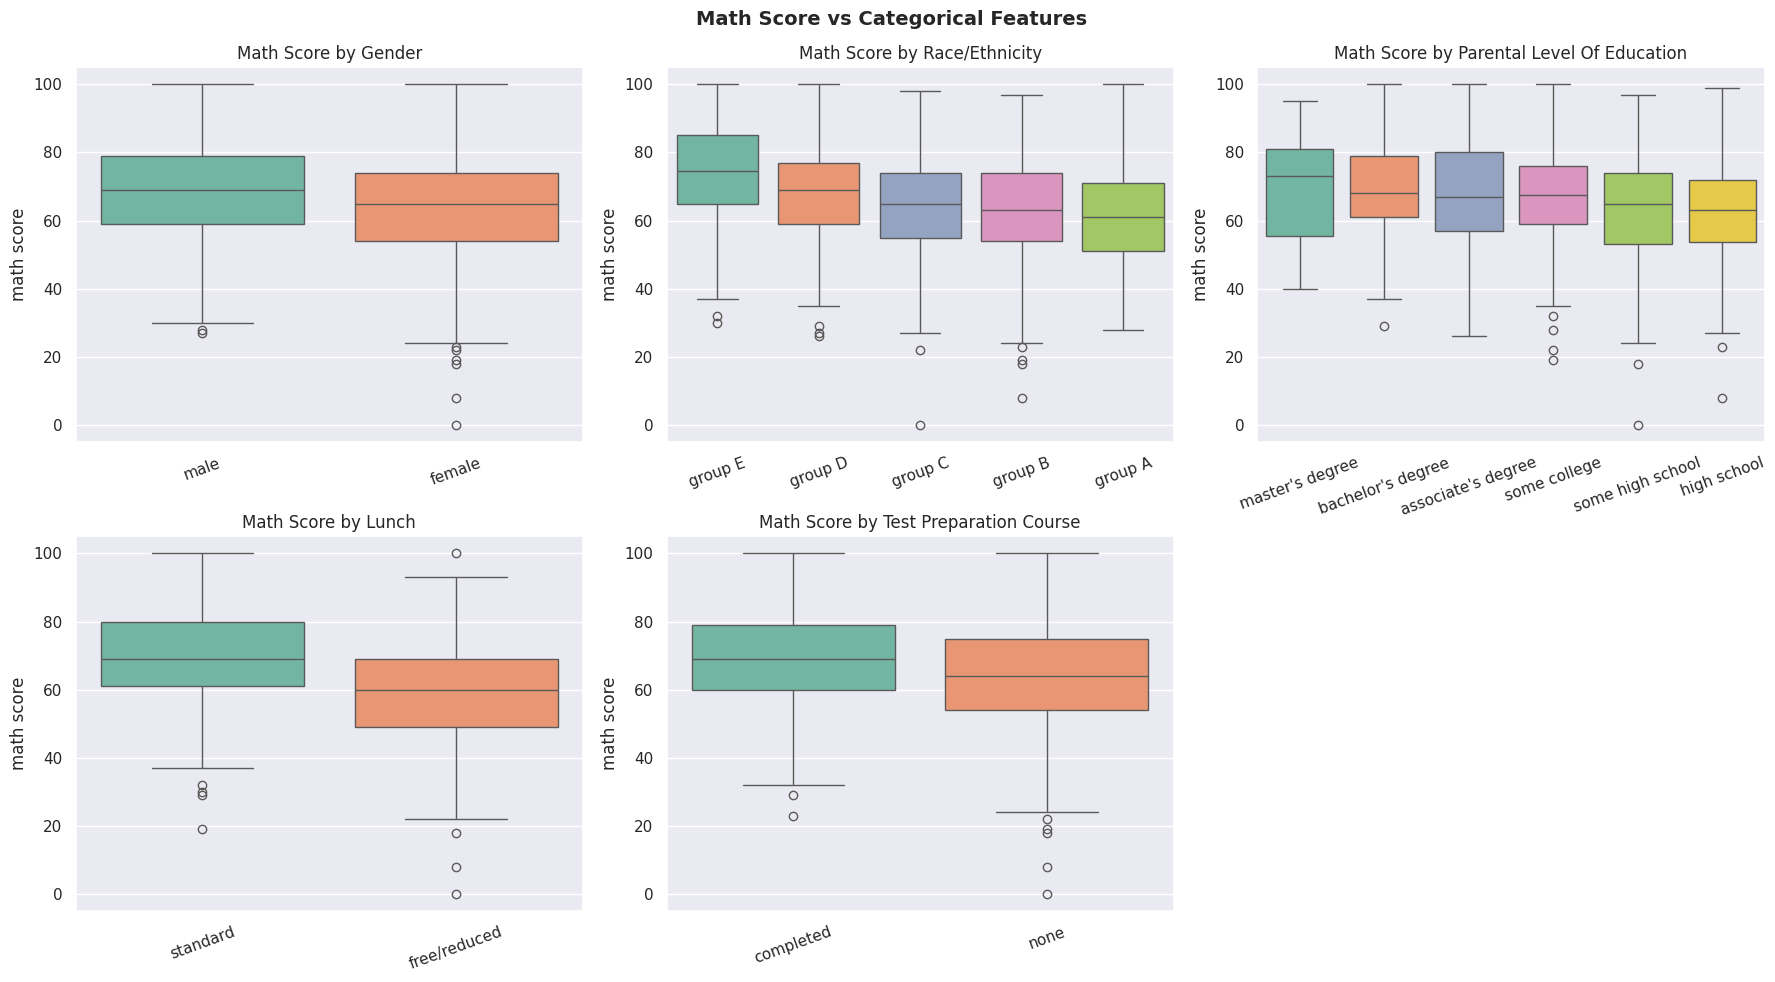


 EDA: Test prep impact 



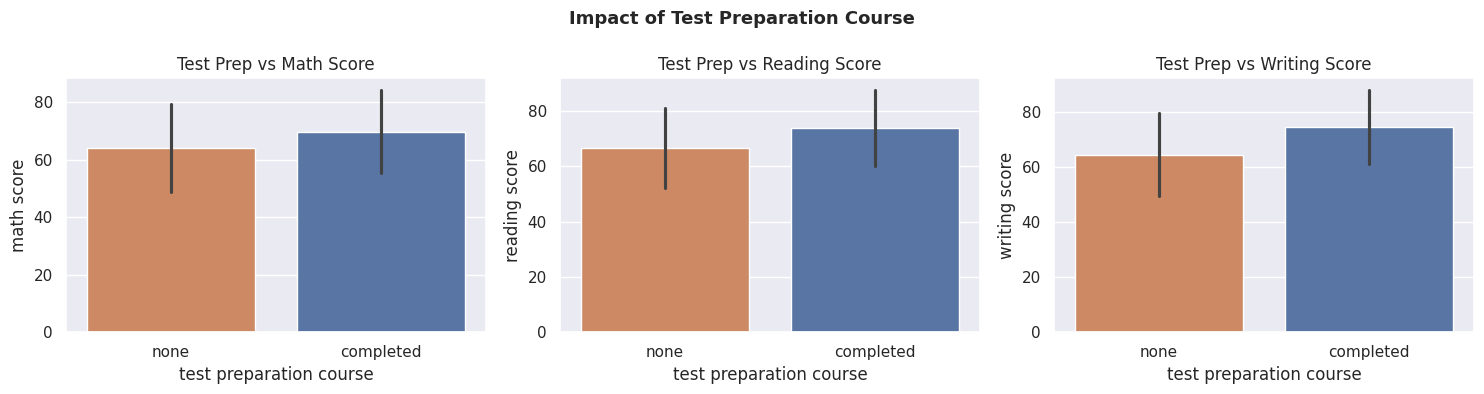

In [ ]:


# ── EDA: Categorical feature analysis ─────────────────────────────────────────
print("\n EDA: Categorical feature analysis: \n")


cat_cols = ['gender', 'race/ethnicity', 'parental level of education',
            'lunch', 'test preparation course']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = df.groupby(col)['math score'].mean().sort_values(ascending=False).index
    sns.boxplot(data=df, x=col, y='math score', order=order, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Math Score by {col.title()}')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=20)

axes[-1].set_visible(False)
plt.suptitle('Math Score vs Categorical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n EDA: Test prep impact \n")

# ── EDA: Test prep impact ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, score in zip(axes, ['math score', 'reading score', 'writing score']):
    sns.barplot(data=df, x='test preparation course', y=score, ax=ax,
                palette=['#DD8452', '#4C72B0'], errorbar='sd')
    ax.set_title(f'Test Prep vs {score.title()}')
plt.suptitle('Impact of Test Preparation Course', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:


## 🔧 Step 3 — Data Preprocessing
print("\n 🔧 Step 3 — Data Preprocessing .....\n")

# ── Clean column names ────────────────────────────────────────────────────────
df.columns = df.columns.str.strip()
print('Columns:', df.columns.tolist())

# ── Check unique values per categorical column ────────────────────────────────
for col in cat_cols:
    print(f'\n{col}: {df[col].unique()}')


# ── No missing values, no duplicates — data is clean! ─────────────────────────
print('Missing values:', df.isnull().sum().sum())
print('Duplicates    :', df.duplicated().sum())
print('\n✅ Data is clean, ready for feature engineering.')


 🔧 Step 3 — Data Preprocessing .....

Columns: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

gender: ['female' 'male']

race/ethnicity: ['group B' 'group C' 'group A' 'group D' 'group E']

parental level of education: ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']

lunch: ['standard' 'free/reduced']

test preparation course: ['none' 'completed']
Missing values: 0
Duplicates    : 0

✅ Data is clean, ready for feature engineering.


In [ ]:

## 🛠️ Step 4 — Feature Engineering
print("\n 🛠️ Step 4 — Feature Engineering .......\n")

df_model = df.copy()

# ── New feature: average of reading + writing ─────────────────────────────────
df_model['avg_rw_score'] = (df_model['reading score'] + df_model['writing score']) / 2

# ── New feature: total score ──────────────────────────────────────────────────
df_model['total_score'] = df_model['math score'] + df_model['reading score'] + df_model['writing score']

# ── New feature: pass/fail flag (for context, not used as feature) ────────────
df_model['pass_flag'] = (df_model['math score'] >= 40).astype(int)

print(df_model[['math score', 'reading score', 'writing score',
                 'avg_rw_score', 'total_score', 'pass_flag']].head())
print('\n✅ New features added: avg_rw_score, total_score, pass_flag')


 🛠️ Step 4 — Feature Engineering .......

   math score  reading score  writing score  avg_rw_score  total_score  \
0          72             72             74          73.0          218   
1          69             90             88          89.0          247   
2          90             95             93          94.0          278   
3          47             57             44          50.5          148   
4          76             78             75          76.5          229   

   pass_flag  
0          1  
1          1  
2          1  
3          1  
4          1  

✅ New features added: avg_rw_score, total_score, pass_flag


In [ ]:


## ✂️ Step 5 — Train / Test Split & Preprocessing Pipeline

print('\n✂️ Step 5 — Train / Test Split & Preprocessing Pipeline....\n\n')


# ── Define features & target ──────────────────────────────────────────────────
TARGET = 'math score'

# Drop target and leak columns (total_score contains math score)
FEATURES = [
    'gender', 'race/ethnicity', 'parental level of education',
    'lunch', 'test preparation course',
    'reading score', 'writing score', 'avg_rw_score'
]

X = df_model[FEATURES]
y = df_model[TARGET]

print(f'Feature matrix shape : {X.shape}')
print(f'Target vector shape  : {y.shape}')
print(f'Target stats         : mean={y.mean():.2f}, std={y.std():.2f}')


# ── Train / Test split ────────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train : {X_train.shape}  |  Test : {X_test.shape}')


# ── Build preprocessing pipeline ─────────────────────────────────────────────

print("\nBuild preprocessing pipeline ...\n\n")


NUM_COLS = ['reading score', 'writing score', 'avg_rw_score']
CAT_COLS = ['gender', 'race/ethnicity', 'parental level of education',
            'lunch', 'test preparation course']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(),                                        NUM_COLS),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
])

print('✅ Preprocessor built')
print(f'   Numerical features  : {NUM_COLS}')
print(f'   Categorical features: {CAT_COLS}')




✂️ Step 5 — Train / Test Split & Preprocessing Pipeline....


Feature matrix shape : (1000, 8)
Target vector shape  : (1000,)
Target stats         : mean=66.09, std=15.16
Train : (800, 8)  |  Test : (200, 8)

Build preprocessing pipeline ...


✅ Preprocessor built
   Numerical features  : ['reading score', 'writing score', 'avg_rw_score']
   Categorical features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [ ]:

## 🤖 Step 6 — Model Training (9 Algorithms)

print("\n 🤖 Step 6 — Model Training (9 Algorithms) ...\n\n")

# ── Define all models ─────────────────────────────────────────────────────────
MODELS = {
    'Linear Regression'   : LinearRegression(),
    'Ridge Regression'    : Ridge(alpha=1.0),
    'Lasso Regression'    : Lasso(alpha=0.01),
    'K-Nearest Neighbors' : KNeighborsRegressor(n_neighbors=5),
    'Decision Tree'       : DecisionTreeRegressor(max_depth=6, random_state=42),
    'Random Forest'       : RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting'   : GradientBoostingRegressor(n_estimators=100, random_state=42),
    'XGBoost'             : XGBRegressor(n_estimators=100, random_state=42, verbosity=0),
    'CatBoost'            : CatBoostRegressor(iterations=100, random_state=42, verbose=0),
}

print(f'✅ {len(MODELS)} models ready for training')


# ── Train all models & collect metrics ───────────────────────────────────────

print("\nTrain all models & collect metrics ...\n\n")
def evaluate_model(pipeline, X_tr, X_te, y_tr, y_te):
    pipeline.fit(X_tr, y_tr)
    preds = pipeline.predict(X_te)
    cv    = cross_val_score(pipeline, X_tr, y_tr, cv=5, scoring='r2')
    return {
        'R2 (Test)'   : round(r2_score(y_te, preds), 4),
        'MAE'         : round(mean_absolute_error(y_te, preds), 4),
        'RMSE'        : round(np.sqrt(mean_squared_error(y_te, preds)), 4),
        'CV R2 (mean)': round(cv.mean(), 4),
        'CV R2 (std)' : round(cv.std(), 4),
    }, pipeline

results  = {}
trained  = {}

print(f'{"Model":<25} {"R2":>8} {"MAE":>8} {"RMSE":>8} {"CV R2":>10}')
print('─' * 65)

for name, estimator in MODELS.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])
    metrics, fitted = evaluate_model(pipe, X_train, X_test, y_train, y_test)
    results[name]   = metrics
    trained[name]   = fitted
    print(f'{name:<25} {metrics["R2 (Test)"]:>8} {metrics["MAE"]:>8} {metrics["RMSE"]:>8} {metrics["CV R2 (mean)"]:>10}')

print('\n✅ All models trained!')




 🤖 Step 6 — Model Training (9 Algorithms) ...


✅ 9 models ready for training

Train all models & collect metrics ...


Model                           R2      MAE     RMSE      CV R2
─────────────────────────────────────────────────────────────────
Linear Regression           0.8804   4.2148    5.394     0.8686
Ridge Regression            0.8806   4.2109   5.3903     0.8686
Lasso Regression            0.8809    4.205   5.3845     0.8686
K-Nearest Neighbors         0.7997    5.433   6.9812     0.7894
Decision Tree               0.8445   4.7619   6.1512     0.7771
Random Forest               0.8449   4.7549   6.1437     0.8327
Gradient Boosting           0.8669   4.3937   5.6903     0.8502
XGBoost                     0.8327    4.919   6.3807     0.7965
CatBoost                    0.8476   4.6475   6.0893      0.842

✅ All models trained!



 📊 Step 7 — Model Evaluation & Comparison ...



── Leaderboard ──

...

──  Color top model ──

...


,Model,R2 (Test),MAE,RMSE,CV R2 (mean),CV R2 (std)
0,Lasso Regression,0.880900,4.205000,5.384500,0.868600,0.011800
1,Ridge Regression,0.880600,4.210900,5.390300,0.868600,0.011800
2,Linear Regression,0.880400,4.214800,5.394000,0.868600,0.011700
3,Gradient Boosting,0.866900,4.393700,5.690300,0.850200,0.005300
4,CatBoost,0.847600,4.647500,6.089300,0.842000,0.014000
5,Random Forest,0.844900,4.754900,6.143700,0.832700,0.016600
6,Decision Tree,0.844500,4.761900,6.151200,0.777100,0.022600
7,XGBoost,0.832700,4.919000,6.380700,0.796500,0.010000
8,K-Nearest Neighbors,0.799700,5.433000,6.981200,0.789400,0.015400



── Visual comparison ──

...


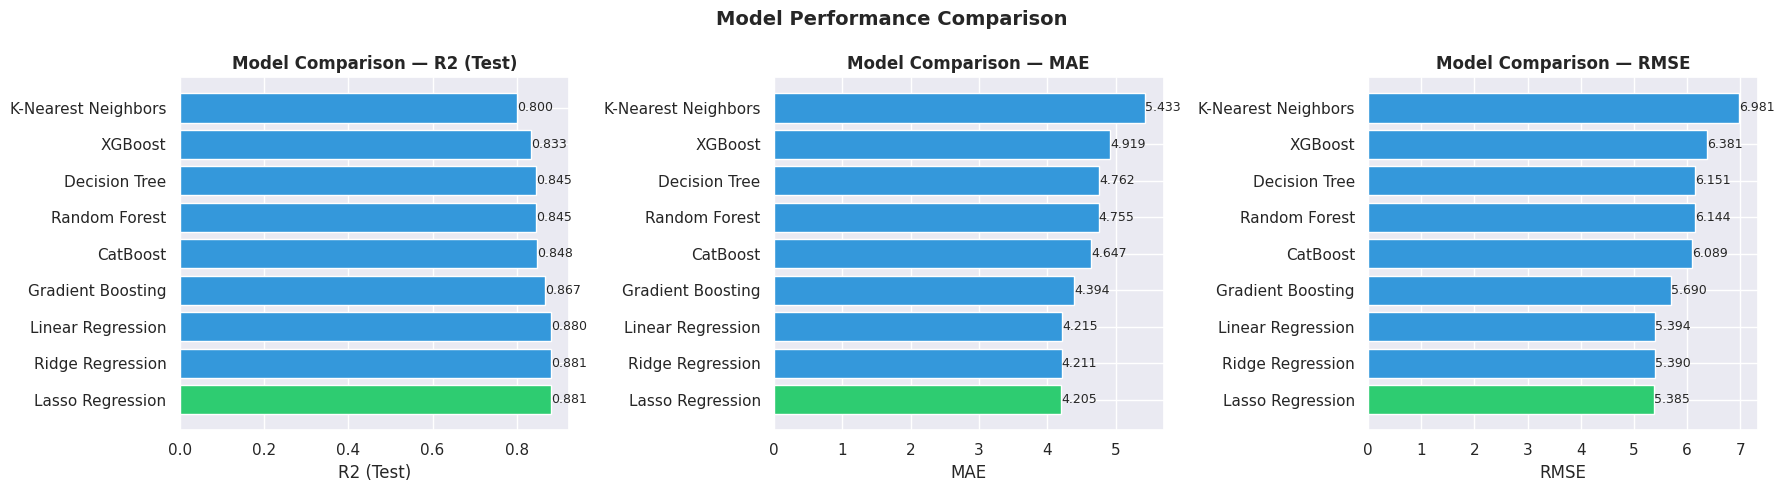


── Actual vs Predicted scatter for best model ──

...
🏆 Best Model: Lasso Regression
   R²  = 0.8809
   MAE = 4.2050
   RMSE= 5.3845

── Actual vs Predicted scatter for best model ──

...


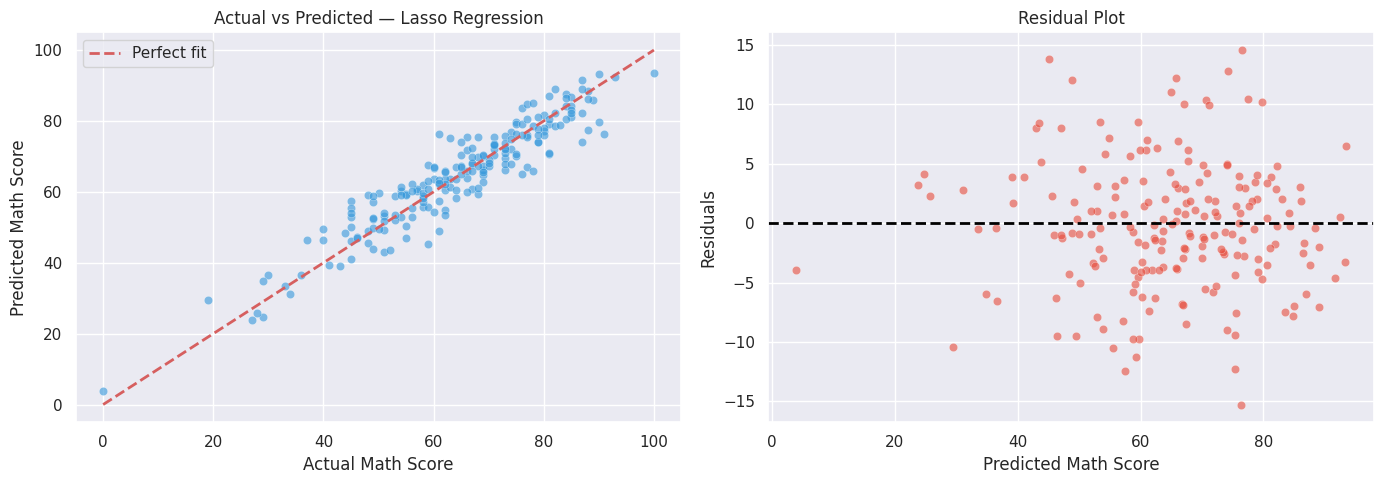

In [ ]:

## 📊 Step 7 — Model Evaluation & Comparison

print("\n 📊 Step 7 — Model Evaluation & Comparison ...\n\n")

# ── Leaderboard ───────────────────────────────────────────────────────────────
print('\n── Leaderboard ──\n\n...')
df_results = pd.DataFrame(results).T.sort_values('R2 (Test)', ascending=False)
df_results.index.name = 'Model'
df_results = df_results.reset_index()

# Color top model
print('\n──  Color top model ──\n\n...')


def highlight_best(s):
    return ['background-color: #d4edda; font-weight: bold' if i == 0 else '' for i in range(len(s))]

display(df_results.style.apply(highlight_best, axis=0))


# ── Visual comparison ─────────────────────────────────────────────────────────
print('\n── Visual comparison ──\n\n...')


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#2ecc71' if i == 0 else '#3498db' for i in range(len(df_results))]

for ax, metric in zip(axes, ['R2 (Test)', 'MAE', 'RMSE']):
    ascending = False if metric == 'R2 (Test)' else True
    data = df_results.sort_values(metric, ascending=ascending)
    bars = ax.barh(data['Model'], data[metric],
                   color=['#2ecc71' if i == 0 else '#3498db' for i in range(len(data))])
    ax.set_title(f'Model Comparison — {metric}', fontweight='bold')
    ax.set_xlabel(metric)
    for bar, val in zip(bars, data[metric]):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=9)

plt.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# ── Actual vs Predicted scatter for best model ────────────────────────────────
print('\n── Actual vs Predicted scatter for best model ──\n\n...')
best_name  = df_results.iloc[0]['Model']
best_model = trained[best_name]
y_pred     = best_model.predict(X_test)

print(f'🏆 Best Model: {best_name}')
print(f'   R²  = {r2_score(y_test, y_pred):.4f}')
print(f'   MAE = {mean_absolute_error(y_test, y_pred):.4f}')
print(f'   RMSE= {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
print('\n── Actual vs Predicted scatter for best model ──\n\n...')



axes[0].scatter(y_test, y_pred, alpha=0.6, color='#3498db', edgecolors='white', linewidth=0.3)
min_v, max_v = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Perfect fit')
axes[0].set_xlabel('Actual Math Score')
axes[0].set_ylabel('Predicted Math Score')
axes[0].set_title(f'Actual vs Predicted — {best_name}')
axes[0].legend()

# Residual plot
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.6, color='#e74c3c', edgecolors='white', linewidth=0.3)
axes[1].axhline(0, color='black', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Math Score')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()



In [ ]:


## 🎯 Step 8 — Hyperparameter Tuning (RandomizedSearchCV on Best Model)

print("\n 🎯 Step 8 — Hyperparameter Tuning (RandomizedSearchCV on Best Model) ...\n\n")

# ── Param grid for Random Forest / GradientBoosting ──────────────────────────
# Adjust based on whichever is your best model

param_grid = {
    'model__n_estimators'      : [50, 100, 150, 200],
    'model__max_depth'         : [None, 5, 10, 15, 20],
    'model__min_samples_split' : [2, 5, 10],
    'model__min_samples_leaf'  : [1, 2, 4],
    'model__max_features'      : ['sqrt', 'log2', None],
}

tune_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

search = RandomizedSearchCV(
    tune_pipe,
    param_grid,
    n_iter      = 30,
    cv          = 5,
    scoring     = 'r2',
    n_jobs      = -1,
    random_state= 42,
    verbose     = 1
)

search.fit(X_train, y_train)

print(f'\n✅ Best CV R²   : {search.best_score_:.4f}')
print(f'   Best Params : {search.best_params_}')


# ── Evaluate tuned model ──────────────────────────────────────────────────────
tuned_model = search.best_estimator_
y_pred_tuned = tuned_model.predict(X_test)

print('═' * 45)
print('  TUNED MODEL — TEST SET RESULTS')
print('═' * 45)
print(f'  R²   = {r2_score(y_test, y_pred_tuned):.4f}')
print(f'  MAE  = {mean_absolute_error(y_test, y_pred_tuned):.4f}')
print(f'  RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_tuned)):.4f}')
print('═' * 45)


 🎯 Step 8 — Hyperparameter Tuning (RandomizedSearchCV on Best Model) ...


Fitting 5 folds for each of 30 candidates, totalling 150 fits

✅ Best CV R²   : 0.8391
   Best Params : {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': None, 'model__max_depth': None}
═════════════════════════════════════════════
  TUNED MODEL — TEST SET RESULTS
═════════════════════════════════════════════
  R²   = 0.8471
  MAE  = 4.6433
  RMSE = 6.0998
═════════════════════════════════════════════


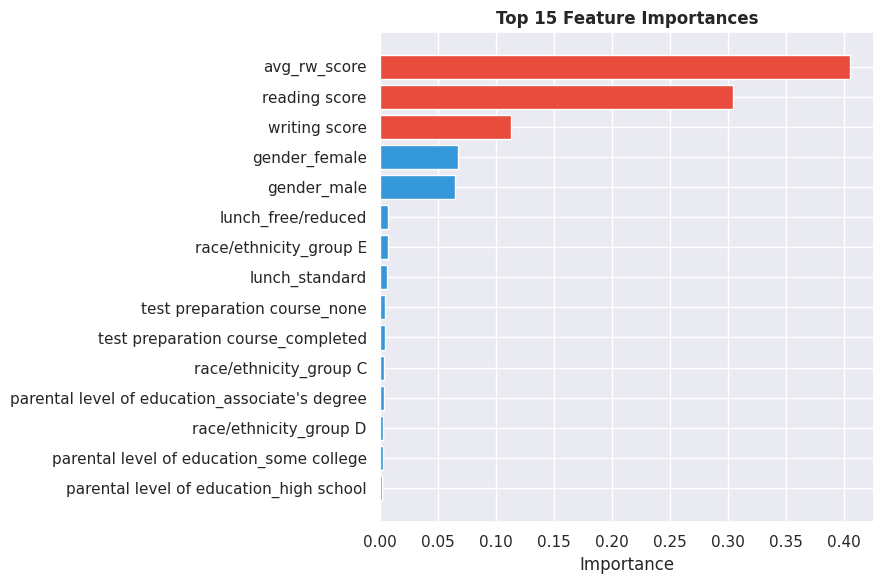

In [ ]:


## 📈 Step 9 — Feature Importance


# ── Extract feature names after OneHotEncoding ────────────────────────────────
try:
    ohe        = tuned_model.named_steps['preprocessor'].named_transformers_['cat']
    cat_feats  = ohe.get_feature_names_out(CAT_COLS).tolist()
    all_feats  = NUM_COLS + cat_feats
    importances= tuned_model.named_steps['model'].feature_importances_

    feat_df = pd.DataFrame({'Feature': all_feats, 'Importance': importances})
    feat_df = feat_df.sort_values('Importance', ascending=True).tail(15)

    plt.figure(figsize=(9, 6))
    plt.barh(feat_df['Feature'], feat_df['Importance'],
             color=['#e74c3c' if 'rw' in f or 'reading' in f or 'writing' in f
                    else '#3498db' for f in feat_df['Feature']])
    plt.xlabel('Importance')
    plt.title('Top 15 Feature Importances', fontweight='bold')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f'Feature importance not available for this model type: {e}')



In [ ]:

## 💾 Step 10 — Save & Load Model

print("\n 💾 Step 10 — Save & Load Model ...\n\n")
# ── Save model ────────────────────────────────────────────────────────────────
MODEL_PATH = 'best_model.pkl'
joblib.dump(tuned_model, MODEL_PATH)
print(f'✅ Model saved → {MODEL_PATH}')

# Download the model file to your PC
from google.colab import files
files.download(MODEL_PATH)
print('✅ Model downloaded to your PC')


# ── Load model & verify ───────────────────────────────────────────────────────
loaded_model = joblib.load(MODEL_PATH)
sample_pred  = loaded_model.predict(X_test[:3])
print('✅ Model loaded successfully!')
print(f'   Sample predictions : {sample_pred.round(2)}')
print(f'   Actual values      : {y_test[:3].values}')




 💾 Step 10 — Save & Load Model ...


✅ Model saved → best_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Model downloaded to your PC
✅ Model loaded successfully!
   Sample predictions : [73.91 57.89 77.28]
   Actual values      : [91 53 80]


In [ ]:
import joblib
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

metrics = {
    "R2": round(r2_score(y_test, y_pred_tuned), 4),
    "MAE": round(mean_absolute_error(y_test, y_pred_tuned), 4),
    "MSE": round(mean_squared_error(y_test, y_pred_tuned), 4)
}

joblib.dump(metrics, "metrics.pkl")
print("Metrics saved successfully!")



Metrics saved successfully!


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Paste this as a NEW CELL in your Colab notebook, right after the cell that
# evaluates the tuned model (the one that prints "TUNED MODEL — TEST SET RESULTS")
# and after the feature-importance cell. Run it, then download metrics.json and
# put it in the project's model/ folder next to student_model.pkl.
#
# It uses variables your notebook already defines:
#   df, X, X_train, X_test, y_test, results, tuned_model, y_pred_tuned, search,
#   NUM_COLS, CAT_COLS
# ─────────────────────────────────────────────────────────────────────────────
import json
import sklearn
from google.colab import files

# 1) feature importances of the deployed (tuned) model, top 8
ohe        = tuned_model.named_steps['preprocessor'].named_transformers_['cat']
feat_names = NUM_COLS + ohe.get_feature_names_out(CAT_COLS).tolist()
importance = tuned_model.named_steps['model'].feature_importances_
top8       = sorted(zip(feat_names, importance), key=lambda t: -t[1])[:8]

# 2) test R² for every model you trained, plus the tuned model
comparison = [{"model": name, "r2": round(float(m["R2 (Test)"]), 4)}
              for name, m in results.items()]
tuned_r2 = round(float(r2_score(y_test, y_pred_tuned)), 4)
comparison.append({"model": "Random Forest (tuned)", "r2": tuned_r2})

# 3) everything the web app shows
metrics = {
    "deployed_model"    : "Random Forest (tuned)",
    "r2"                : tuned_r2,
    "mae"               : round(float(mean_absolute_error(y_test, y_pred_tuned)), 2),
    "rmse"              : round(float(np.sqrt(mean_squared_error(y_test, y_pred_tuned))), 2),
    "cv_r2"             : round(float(search.best_score_), 4),
    "train_size"        : int(len(X_train)),
    "test_size"         : int(len(X_test)),
    "total_rows"        : int(len(df)),
    "n_features"        : int(X.shape[1]),
    "sklearn_version"   : sklearn.__version__,
    "model_comparison"  : comparison,
    "feature_importance": {k: round(float(v), 3) for k, v in top8},
}

with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))
print("\nscikit-learn used for training:", sklearn.__version__)
print("-> make sure requirements.txt pins scikit-learn==" + sklearn.__version__)
files.download("metrics.json")


{
  "deployed_model": "Random Forest (tuned)",
  "r2": 0.8471,
  "mae": 4.64,
  "rmse": 6.1,
  "cv_r2": 0.8391,
  "train_size": 800,
  "test_size": 200,
  "total_rows": 1000,
  "n_features": 8,
  "sklearn_version": "1.6.1",
  "model_comparison": [
    {
      "model": "Linear Regression",
      "r2": 0.8804
    },
    {
      "model": "Ridge Regression",
      "r2": 0.8806
    },
    {
      "model": "Lasso Regression",
      "r2": 0.8809
    },
    {
      "model": "K-Nearest Neighbors",
      "r2": 0.7997
    },
    {
      "model": "Decision Tree",
      "r2": 0.8445
    },
    {
      "model": "Random Forest",
      "r2": 0.8449
    },
    {
      "model": "Gradient Boosting",
      "r2": 0.8669
    },
    {
      "model": "XGBoost",
      "r2": 0.8327
    },
    {
      "model": "CatBoost",
      "r2": 0.8476
    },
    {
      "model": "Random Forest (tuned)",
      "r2": 0.8471
    }
  ],
  "feature_importance": {
    "avg_rw_score": 0.406,
    "reading score": 0.305,
    "writi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# # #Text cell <undefined>
# # # %% [markdown]
# # # 🎓 Student Performance Predictor — Complete ML Pipeline
# # **Target:** Predict `math score` from student background features
# # **Dataset:** StudentsPerformance.csv (1000 rows)

# # ---
# # ### 📋 Table of Contents
# # 1. Install & Import Libraries
# # 2. Load & Explore Data (EDA)
# # 3. Data Preprocessing
# # 4. Feature Engineering
# # 5. Train / Test Split
# # 6. Model Training (7 Models)
# # 7. Model Evaluation & Comparison
# # 8. Hyperparameter Tuning
# # 9. Final Model Evaluation
# # 10. Save & Load Model
# # 11. Predict on New Data

# # Text cell <undefined>
# # # %% [markdown]
# ## ⚙️ Step 1 — Install & Import Libraries

# #Code cell <undefined>

# # Install extra libraries (xgboost already available in Colab)
# #!pip install -q xgboost catboost

# # ── Core ──────────────────────────────────────────────────────────────────────
# import numpy as np
# import pandas as pd
# import warnings
# warnings.filterwarnings('ignore')

# # ── Visualization ─────────────────────────────────────────────────────────────
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# import seaborn as sns
# sns.set_theme(style='darkgrid', palette='muted')
# %matplotlib inline

# # ── Sklearn ───────────────────────────────────────────────────────────────────
# from sklearn.model_selection       import train_test_split, cross_val_score, RandomizedSearchCV
# from sklearn.preprocessing         import OneHotEncoder, StandardScaler, LabelEncoder
# from sklearn.compose               import ColumnTransformer
# from sklearn.pipeline              import Pipeline
# from sklearn.metrics               import r2_score, mean_absolute_error, mean_squared_error

# from sklearn.linear_model          import LinearRegression, Ridge, Lasso
# from sklearn.tree                  import DecisionTreeRegressor
# from sklearn.ensemble              import RandomForestRegressor, GradientBoostingRegressor
# from sklearn.neighbors             import KNeighborsRegressor

# from xgboost  import XGBRegressor
# from catboost import CatBoostRegressor

# import joblib

# print('✅ All libraries imported successfully!')

# Text cell <undefined>
# # %% [markdown]
# ## 📂 Step 2 — Load & Explore Data (EDA)

# Code cell <undefined>
# # %% [code]
# # ── Upload your CSV file ──────────────────────────────────────────────────────
# # METHOD A: Upload manually
# from google.colab import files
# uploaded = files.upload()   # <-- click 'Choose File' and upload StudentsPerformance.csv

# # Load the file
# import io
# df = pd.read_csv(io.BytesIO(uploaded['StudentsPerformance.csv']))

# # -------------------------------------------------------------------
# # METHOD B: If already in Colab /content folder, use this instead:
# # df = pd.read_csv('/content/StudentsPerformance.csv')
# # -------------------------------------------------------------------

# print(f'✅ Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns')
# df.head()

# Code cell <undefined>
# # %% [code]
# # ── Basic info ────────────────────────────────────────────────────────────────
# print('── Shape ──')
# print(df.shape)

# print('\n── Data Types ──')
# print(df.dtypes)

# print('\n── Missing Values ──')
# print(df.isnull().sum())

# print('\n── Duplicates ──')
# print(f'Duplicate rows: {df.duplicated().sum()}')

# Code cell <undefined>
# # %% [code]
# # ── Descriptive statistics ────────────────────────────────────────────────────
# df.describe().round(2)

# Code cell <undefined>
# # %% [code]

# # ── EDA: Score distributions ──────────────────────────────────────────────────
# fig, axes = plt.subplots(1, 3, figsize=(16, 4))
# colors = ['#4C72B0', '#DD8452', '#55A868']

# for ax, col, c in zip(axes, ['math score', 'reading score', 'writing score'], colors):
#     sns.histplot(df[col], kde=True, ax=ax, color=c, bins=20)
#     ax.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.1f}')
#     ax.set_title(f'{col.title()} Distribution')
#     ax.legend()

# plt.suptitle('Score Distributions', fontsize=14, fontweight='bold', y=1.02)
# plt.tight_layout()
# plt.show()

# Code cell <undefined>
# # %% [code]
# # ── EDA: Correlation heatmap ──────────────────────────────────────────────────
# plt.figure(figsize=(6, 4))
# corr = df[['math score', 'reading score', 'writing score']].corr()
# sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, square=True)
# plt.title('Score Correlation Heatmap', fontweight='bold')
# plt.tight_layout()
# plt.show()

# Code cell <undefined>
# # %% [code]
# # ── EDA: Categorical feature analysis ─────────────────────────────────────────
# cat_cols = ['gender', 'race/ethnicity', 'parental level of education',
#             'lunch', 'test preparation course']

# fig, axes = plt.subplots(2, 3, figsize=(18, 10))
# axes = axes.flatten()

# for i, col in enumerate(cat_cols):
#     order = df.groupby(col)['math score'].mean().sort_values(ascending=False).index
#     sns.boxplot(data=df, x=col, y='math score', order=order, ax=axes[i], palette='Set2')
#     axes[i].set_title(f'Math Score by {col.title()}')
#     axes[i].set_xlabel('')
#     axes[i].tick_params(axis='x', rotation=20)

# axes[-1].set_visible(False)
# plt.suptitle('Math Score vs Categorical Features', fontsize=14, fontweight='bold')
# plt.tight_layout()
# plt.show()

# Code cell <undefined>
# # %% [code]
# # ── EDA: Test prep impact ─────────────────────────────────────────────────────
# fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# for ax, score in zip(axes, ['math score', 'reading score', 'writing score']):
#     sns.barplot(data=df, x='test preparation course', y=score, ax=ax,
#                 palette=['#DD8452', '#4C72B0'], errorbar='sd')
#     ax.set_title(f'Test Prep vs {score.title()}')
# plt.suptitle('Impact of Test Preparation Course', fontsize=13, fontweight='bold')
# plt.tight_layout()
# plt.show()

# Text cell <undefined>
# # %% [markdown]
# ## 🔧 Step 3 — Data Preprocessing

# Code cell <undefined>
# # %% [code]
# # ── Clean column names ────────────────────────────────────────────────────────
# df.columns = df.columns.str.strip()
# print('Columns:', df.columns.tolist())

# # ── Check unique values per categorical column ────────────────────────────────
# for col in cat_cols:
#     print(f'\n{col}: {df[col].unique()}')

# Code cell <undefined>
# # %% [code]
# # ── No missing values, no duplicates — data is clean! ─────────────────────────
# print('Missing values:', df.isnull().sum().sum())
# print('Duplicates    :', df.duplicated().sum())
# print('\n✅ Data is clean, ready for feature engineering.')


# ## 🛠️ Step 4 — Feature Engineering

# Code cell <undefined>
# # %% [code]
# df_model = df.copy()

# # ── New feature: average of reading + writing ─────────────────────────────────
# df_model['avg_rw_score'] = (df_model['reading score'] + df_model['writing score']) / 2

# # ── New feature: total score ──────────────────────────────────────────────────
# df_model['total_score'] = df_model['math score'] + df_model['reading score'] + df_model['writing score']

# # ── New feature: pass/fail flag (for context, not used as feature) ────────────
# df_model['pass_flag'] = (df_model['math score'] >= 40).astype(int)

# print(df_model[['math score', 'reading score', 'writing score',
#                  'avg_rw_score', 'total_score', 'pass_flag']].head())
# print('\n✅ New features added: avg_rw_score, total_score, pass_flag')




# ## ✂️ Step 5 — Train / Test Split & Preprocessing Pipeline

# Code cell <undefined>
# # %% [code]
# # ── Define features & target ──────────────────────────────────────────────────
# TARGET = 'math score'

# # Drop target and leak columns (total_score contains math score)
# FEATURES = [
#     'gender', 'race/ethnicity', 'parental level of education',
#     'lunch', 'test preparation course',
#     'reading score', 'writing score', 'avg_rw_score'
# ]

# X = df_model[FEATURES]
# y = df_model[TARGET]

# print(f'Feature matrix shape : {X.shape}')
# print(f'Target vector shape  : {y.shape}')
# print(f'Target stats         : mean={y.mean():.2f}, std={y.std():.2f}')

# Code cell <undefined>
# # %% [code]
# # ── Train / Test split ────────────────────────────────────────────────────────
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )
# print(f'Train : {X_train.shape}  |  Test : {X_test.shape}')

# Code cell <undefined>
# # %% [code]
# # ── Build preprocessing pipeline ─────────────────────────────────────────────
# NUM_COLS = ['reading score', 'writing score', 'avg_rw_score']
# CAT_COLS = ['gender', 'race/ethnicity', 'parental level of education',
#             'lunch', 'test preparation course']

# preprocessor = ColumnTransformer(transformers=[
#     ('num', StandardScaler(),                                        NUM_COLS),
#     ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
# ])

# print('✅ Preprocessor built')
# print(f'   Numerical features  : {NUM_COLS}')
# print(f'   Categorical features: {CAT_COLS}')

# Text cell <undefined>
# # %% [markdown]

# ## 🤖 Step 6 — Model Training (9 Algorithms)

# Code cell <undefined>
# # %% [code]
# # ── Define all models ─────────────────────────────────────────────────────────
# MODELS = {
#     'Linear Regression'   : LinearRegression(),
#     'Ridge Regression'    : Ridge(alpha=1.0),
#     'Lasso Regression'    : Lasso(alpha=0.01),
#     'K-Nearest Neighbors' : KNeighborsRegressor(n_neighbors=5),
#     'Decision Tree'       : DecisionTreeRegressor(max_depth=6, random_state=42),
#     'Random Forest'       : RandomForestRegressor(n_estimators=100, random_state=42),
#     'Gradient Boosting'   : GradientBoostingRegressor(n_estimators=100, random_state=42),
#     'XGBoost'             : XGBRegressor(n_estimators=100, random_state=42, verbosity=0),
#     'CatBoost'            : CatBoostRegressor(iterations=100, random_state=42, verbose=0),
# }

# print(f'✅ {len(MODELS)} models ready for training')

# Code cell <undefined>
# # %% [code]
# # ── Train all models & collect metrics ───────────────────────────────────────
# def evaluate_model(pipeline, X_tr, X_te, y_tr, y_te):
#     pipeline.fit(X_tr, y_tr)
#     preds = pipeline.predict(X_te)
#     cv    = cross_val_score(pipeline, X_tr, y_tr, cv=5, scoring='r2')
#     return {
#         'R2 (Test)'   : round(r2_score(y_te, preds), 4),
#         'MAE'         : round(mean_absolute_error(y_te, preds), 4),
#         'RMSE'        : round(np.sqrt(mean_squared_error(y_te, preds)), 4),
#         'CV R2 (mean)': round(cv.mean(), 4),
#         'CV R2 (std)' : round(cv.std(), 4),
#     }, pipeline

# results  = {}
# trained  = {}

# print(f'{"Model":<25} {"R2":>8} {"MAE":>8} {"RMSE":>8} {"CV R2":>10}')
# print('─' * 65)

# for name, estimator in MODELS.items():
#     pipe = Pipeline([
#         ('preprocessor', preprocessor),
#         ('model', estimator)
#     ])
#     metrics, fitted = evaluate_model(pipe, X_train, X_test, y_train, y_test)
#     results[name]   = metrics
#     trained[name]   = fitted
#     print(f'{name:<25} {metrics["R2 (Test)"]:>8} {metrics["MAE"]:>8} {metrics["RMSE"]:>8} {metrics["CV R2 (mean)"]:>10}')

# print('\n✅ All models trained!')




# Text cell <undefined>
# # %% [markdown]
# ## 📊 Step 7 — Model Evaluation & Comparison

# Code cell <undefined>
# # %% [code]
# # ── Leaderboard ───────────────────────────────────────────────────────────────
# df_results = pd.DataFrame(results).T.sort_values('R2 (Test)', ascending=False)
# df_results.index.name = 'Model'
# df_results = df_results.reset_index()

# # Color top model
# def highlight_best(s):
#     return ['background-color: #d4edda; font-weight: bold' if i == 0 else '' for i in range(len(s))]

# display(df_results.style.apply(highlight_best, axis=0))

# Code cell <undefined>
# # %% [code]
# # ── Visual comparison ─────────────────────────────────────────────────────────
# fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# colors = ['#2ecc71' if i == 0 else '#3498db' for i in range(len(df_results))]

# for ax, metric in zip(axes, ['R2 (Test)', 'MAE', 'RMSE']):
#     ascending = False if metric == 'R2 (Test)' else True
#     data = df_results.sort_values(metric, ascending=ascending)
#     bars = ax.barh(data['Model'], data[metric],
#                    color=['#2ecc71' if i == 0 else '#3498db' for i in range(len(data))])
#     ax.set_title(f'Model Comparison — {metric}', fontweight='bold')
#     ax.set_xlabel(metric)
#     for bar, val in zip(bars, data[metric]):
#         ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
#                 f'{val:.3f}', va='center', fontsize=9)

# plt.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
# plt.tight_layout()
# plt.show()

# Code cell <undefined>
# # %% [code]
# # ── Actual vs Predicted scatter for best model ────────────────────────────────
# best_name  = df_results.iloc[0]['Model']
# best_model = trained[best_name]
# y_pred     = best_model.predict(X_test)

# print(f'🏆 Best Model: {best_name}')
# print(f'   R²  = {r2_score(y_test, y_pred):.4f}')
# print(f'   MAE = {mean_absolute_error(y_test, y_pred):.4f}')
# print(f'   RMSE= {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}')

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# # Actual vs Predicted
# axes[0].scatter(y_test, y_pred, alpha=0.6, color='#3498db', edgecolors='white', linewidth=0.3)
# min_v, max_v = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
# axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Perfect fit')
# axes[0].set_xlabel('Actual Math Score')
# axes[0].set_ylabel('Predicted Math Score')
# axes[0].set_title(f'Actual vs Predicted — {best_name}')
# axes[0].legend()

# # Residual plot
# residuals = y_test - y_pred
# axes[1].scatter(y_pred, residuals, alpha=0.6, color='#e74c3c', edgecolors='white', linewidth=0.3)
# axes[1].axhline(0, color='black', linestyle='--', lw=2)
# axes[1].set_xlabel('Predicted Math Score')
# axes[1].set_ylabel('Residuals')
# axes[1].set_title('Residual Plot')

# plt.tight_layout()
# plt.show()

# Text cell <undefined>
# # %% [markdown]
# ## 🎯 Step 8 — Hyperparameter Tuning (RandomizedSearchCV on Best Model)

# Code cell <undefined>
# # %% [code]
# # ── Param grid for Random Forest / GradientBoosting ──────────────────────────
# # Adjust based on whichever is your best model

# param_grid = {
#     'model__n_estimators'      : [50, 100, 150, 200],
#     'model__max_depth'         : [None, 5, 10, 15, 20],
#     'model__min_samples_split' : [2, 5, 10],
#     'model__min_samples_leaf'  : [1, 2, 4],
#     'model__max_features'      : ['sqrt', 'log2', None],
# }

# tune_pipe = Pipeline([
#     ('preprocessor', preprocessor),
#     ('model', RandomForestRegressor(random_state=42))
# ])

# search = RandomizedSearchCV(
#     tune_pipe,
#     param_grid,
#     n_iter      = 30,
#     cv          = 5,
#     scoring     = 'r2',
#     n_jobs      = -1,
#     random_state= 42,
#     verbose     = 1
# )

# search.fit(X_train, y_train)

# print(f'\n✅ Best CV R²   : {search.best_score_:.4f}')
# print(f'   Best Params : {search.best_params_}')

# Code cell <undefined>
# # %% [code]
# # ── Evaluate tuned model ──────────────────────────────────────────────────────
# tuned_model = search.best_estimator_
# y_pred_tuned = tuned_model.predict(X_test)

# print('═' * 45)
# print('  TUNED MODEL — TEST SET RESULTS')
# print('═' * 45)
# print(f'  R²   = {r2_score(y_test, y_pred_tuned):.4f}')
# print(f'  MAE  = {mean_absolute_error(y_test, y_pred_tuned):.4f}')
# print(f'  RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_tuned)):.4f}')
# print('═' * 45)

# Text cell <undefined>
# # %% [markdown]
# ## 📈 Step 9 — Feature Importance

# Code cell <undefined>
# # %% [code]
# # ── Extract feature names after OneHotEncoding ────────────────────────────────
# try:
#     ohe        = tuned_model.named_steps['preprocessor'].named_transformers_['cat']
#     cat_feats  = ohe.get_feature_names_out(CAT_COLS).tolist()
#     all_feats  = NUM_COLS + cat_feats
#     importances= tuned_model.named_steps['model'].feature_importances_

#     feat_df = pd.DataFrame({'Feature': all_feats, 'Importance': importances})
#     feat_df = feat_df.sort_values('Importance', ascending=True).tail(15)

#     plt.figure(figsize=(9, 6))
#     plt.barh(feat_df['Feature'], feat_df['Importance'],
#              color=['#e74c3c' if 'rw' in f or 'reading' in f or 'writing' in f
#                     else '#3498db' for f in feat_df['Feature']])
#     plt.xlabel('Importance')
#     plt.title('Top 15 Feature Importances', fontweight='bold')
#     plt.tight_layout()
#     plt.show()
# except Exception as e:
#     print(f'Feature importance not available for this model type: {e}')

# Text cell <undefined>
# # %% [markdown]

# ## 💾 Step 10 — Save & Load Model

# Code cell <undefined>
# # %% [code]
# # ── Save model ────────────────────────────────────────────────────────────────
# MODEL_PATH = 'best_model.pkl'
# joblib.dump(tuned_model, MODEL_PATH)
# print(f'✅ Model saved → {MODEL_PATH}')

# # Download the model file to your PC
# from google.colab import files
# files.download(MODEL_PATH)
# print('✅ Model downloaded to your PC')

# Code cell <undefined>
# # %% [code]
# # ── Load model & verify ───────────────────────────────────────────────────────
# loaded_model = joblib.load(MODEL_PATH)
# sample_pred  = loaded_model.predict(X_test[:3])
# print('✅ Model loaded successfully!')
# print(f'   Sample predictions : {sample_pred.round(2)}')
# print(f'   Actual values      : {y_test[:3].values}')

# Text cell <undefined>
# # %% [markdown]
# ## 🔮 Step 11 — Predict on New / Custom Data

# Code cell <undefined>
# # %% [code]
# # ── Predict a single student ──────────────────────────────────────────────────
# def predict_student(gender, race_ethnicity, parental_education,
#                     lunch, test_prep, reading_score, writing_score):
#     avg_rw = (reading_score + writing_score) / 2
#     data = pd.DataFrame([{
#         'gender'                      : gender,
#         'race/ethnicity'              : race_ethnicity,
#         'parental level of education' : parental_education,
#         'lunch'                       : lunch,
#         'test preparation course'     : test_prep,
#         'reading score'               : reading_score,
#         'writing score'               : writing_score,
#         'avg_rw_score'                : avg_rw,
#     }])
#     pred  = round(float(loaded_model.predict(data)[0]), 2)
#     grade = ('A+' if pred>=90 else 'A' if pred>=80 else 'B' if pred>=70
#               else 'C' if pred>=60 else 'D' if pred>=50 else 'F')
#     print('─' * 40)
#     print(f'  Predicted Math Score : {pred} / 100')
#     print(f'  Grade                : {grade}')
#     print('─' * 40)
#     return pred

# # ── Example 1 ────────────────────────────────────────────────────────────────
# print('Example 1 — Female, completed test prep')
# predict_student(
#     gender             = 'female',
#     race_ethnicity     = 'group B',
#     parental_education = "bachelor's degree",
#     lunch              = 'standard',
#     test_prep          = 'completed',
#     reading_score      = 72,
#     writing_score      = 74
# )

# # ── Example 2 ────────────────────────────────────────────────────────────────
# print('Example 2 — Male, no test prep, free lunch')
# predict_student(
#     gender             = 'male',
#     race_ethnicity     = 'group A',
#     parental_education = 'high school',
#     lunch              = 'free/reduced',
#     test_prep          = 'none',
#     reading_score      = 45,
#     writing_score      = 42
# )

# Code cell <undefined>
# # %% [code]
# # ── Batch predictions on test set ─────────────────────────────────────────────
# df_test_results = X_test.copy()
# df_test_results['actual_math_score']    = y_test.values
# df_test_results['predicted_math_score'] = loaded_model.predict(X_test).round(2)
# df_test_results['error']                = (df_test_results['actual_math_score'] -
#                                             df_test_results['predicted_math_score']).abs().round(2)

# print(f'Average prediction error: {df_test_results["error"].mean():.2f} marks')
# df_test_results.head(10)

# Text cell <undefined>
# # %% [markdown]
# ---
# ## ✅ Summary

# | Step | What we did |
# |------|-------------|
# | 1 | Installed libraries |
# | 2 | Loaded CSV & did EDA (plots, correlations) |
# | 3 | Cleaned data — no missing values found |
# | 4 | Added avg_rw_score feature |
# | 5 | Train/Test split + ColumnTransformer |
# | 6 | Trained 9 models |
# | 7 | Compared by R², MAE, RMSE |
# | 8 | Tuned best model with RandomizedSearchCV |
# | 9 | Visualized feature importances |
# | 10 | Saved model as best_model.pkl |
# | 11 | Made predictions on custom input |

# **Model file `best_model.pkl` is ready for deployment!** 🚀

# Notebook attributes
# Show table of contents
